# Notebook to setup the radcalnet_oc package

In [1]:

import os, shutil
import glob

import matplotlib as mpl
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1.inset_locator import inset_axes
rc = {"font.family": "serif",
      "mathtext.fontset": "stix"}
plt.rcParams.update(rc)
plt.rcParams["font.serif"] = ["Times New Roman"] + plt.rcParams["font.serif"]

plt.rcParams.update({'font.size': 18, 'axes.labelsize': 22})
import numpy as np
import xarray as xr
import pandas as pd

import radcalnet_oc as radoc
from radcalnet_oc import kernel
print(f'-radcalnet_oc: {radoc.__version__}')


-radcalnet_oc: 0.0.1


## Plot the solar extraterrestrial irradiance from different data sources (TSIS is recommended)

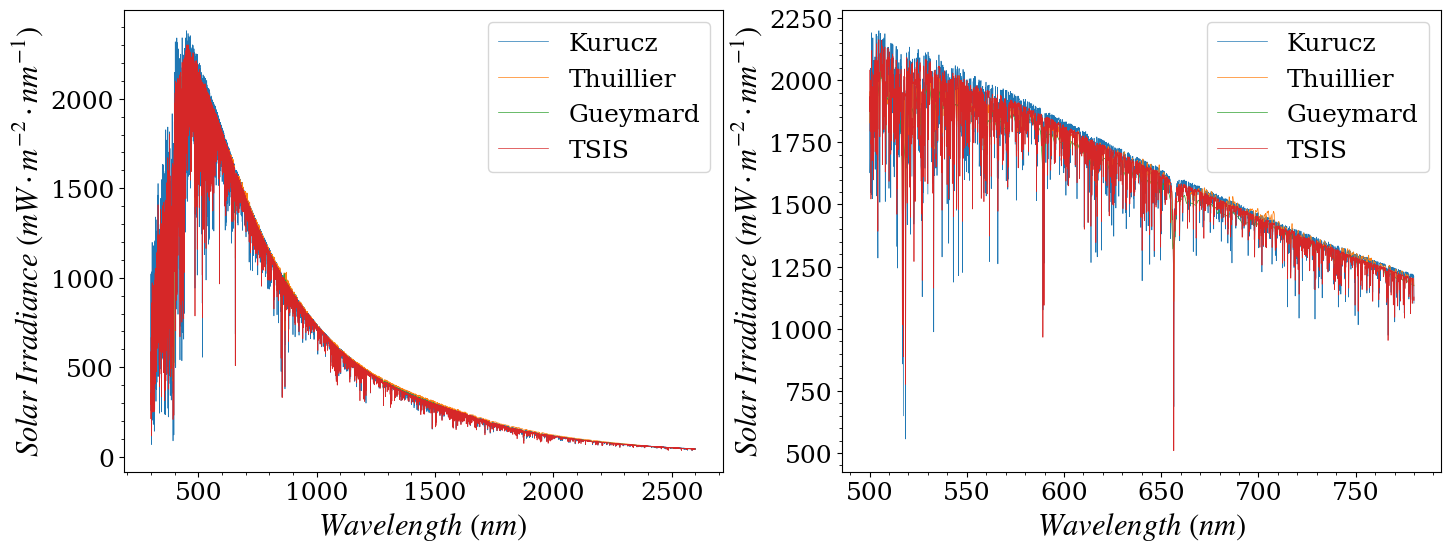

In [2]:
solar_irr=radoc.SolarIrradiance()
fig,axs = plt.subplots(1,2,figsize=(17,6))

solar_irr.kurucz.plot(lw=0.5,ax=axs[0],label='Kurucz')
solar_irr.thuillier.plot(lw=0.5,ax=axs[0],label='Thuillier')
solar_irr.gueymard.plot(lw=0.5,ax=axs[0],label='Gueymard')
solar_irr.tsis.plot(lw=0.5,ax=axs[0],label='TSIS')

axs[0].legend()

wl_range=slice(500,780)
solar_irr.kurucz.sel(wl=wl_range).plot(lw=0.5,ax=axs[1],label='Kurucz')
solar_irr.thuillier.sel(wl=wl_range).plot(lw=0.5,ax=axs[1],label='Thuillier')
solar_irr.gueymard.sel(wl=wl_range).plot(lw=0.5,ax=axs[1],label='Gueymard')
solar_irr.tsis.sel(wl=wl_range).plot(lw=0.5,ax=axs[1],label='TSIS')
axs[1].legend()

for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Solar\ Irradiance\ (mW\cdot m^{-2}\cdot nm^{-1})$')
    ax.minorticks_on()
    #ax.semilogy()

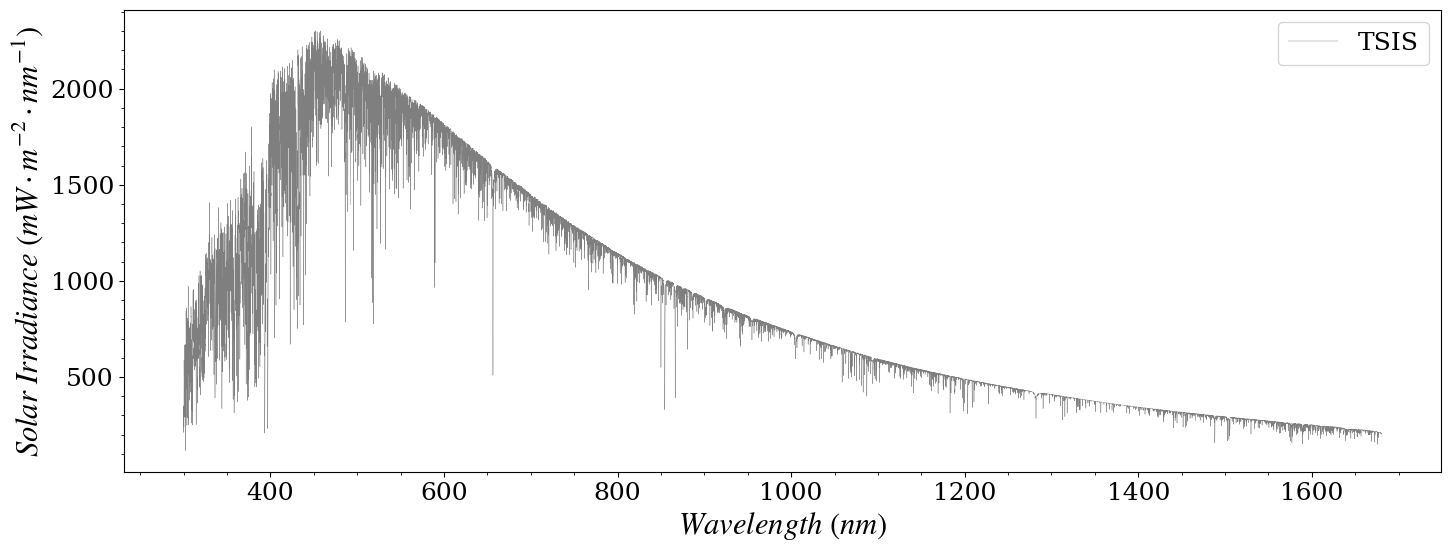

In [3]:
solar_irr=radoc.SolarIrradiance()
fig,ax = plt.subplots(1,1,figsize=(17,6))


wl_range=slice(300,1680)
#solar_irr.kurucz.sel(wl=wl_range).plot(lw=0.5,ax=axs[1],label='Kurucz')
#solar_irr.thuillier.sel(wl=wl_range).plot(lw=0.5,ax=axs[1],label='Thuillier')
#solar_irr.gueymard.sel(wl=wl_range).plot(lw=0.5,ax=axs[1],label='Gueymard')
solar_irr.tsis.sel(wl=wl_range).plot(lw=0.3,c='k',ax=ax,label='TSIS',alpha=0.5)
ax.legend()


ax.set_xlabel(r'$Wavelength\ (nm)$')
ax.set_ylabel(r'$Solar\ Irradiance\ (mW\cdot m^{-2}\cdot nm^{-1})$')
ax.minorticks_on()
    #ax.semilogy()

## Check impact of the spectral resolution (sensor-like)
Spectral resolution is defined by the number (central wavelength: `central_wl`) and width (gaussian distribution) of spectral bands recorded. The gaussian distribution are computed from the full width at half maximum `fwhm` given in nanometers.

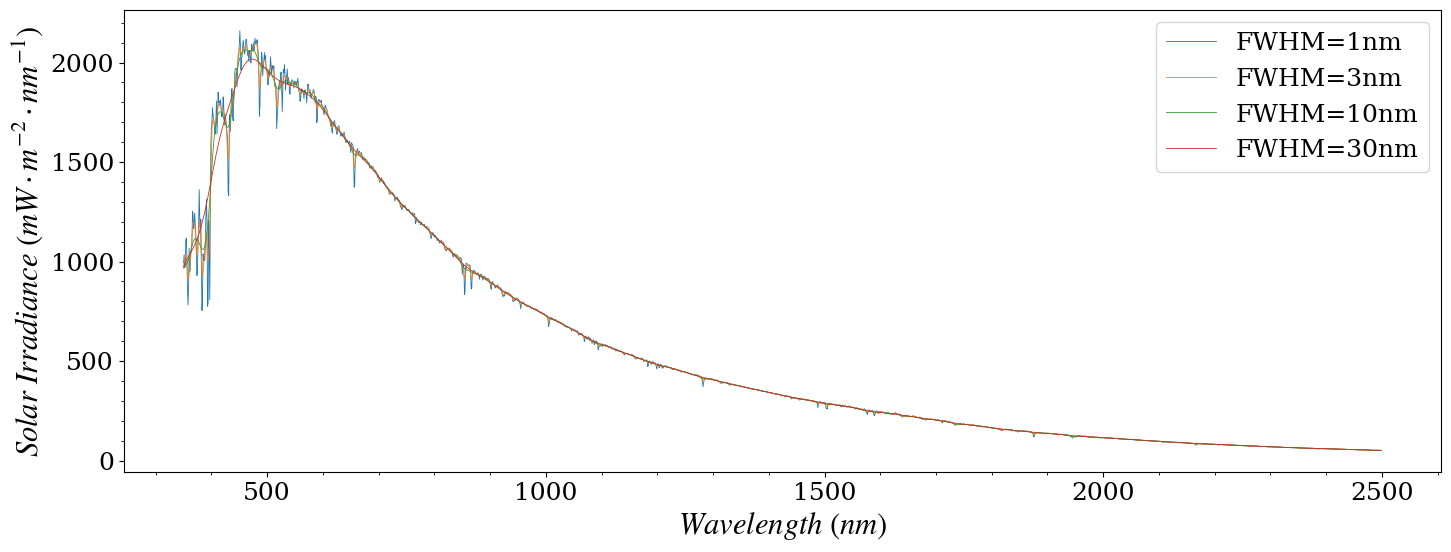

In [4]:

spectral_res=1
central_wl=np.arange(350,2500,spectral_res)

signal = solar_irr.tsis
wl_signal = solar_irr.tsis.wl.values

fig,axs = plt.subplots(1,1,figsize=(17,6))
wl_range=slice(350,1680)
for fwhm in [1,3,10,30]:    
    spectral=radoc.Spectral(central_wl,fwhm)
    F0 = spectral.convolve(signal)
    F0.plot(lw=0.6,label='FWHM='+str(fwhm)+'nm',ax=axs)
    

for ax in  [axs]:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Solar\ Irradiance\ (mW\cdot m^{-2}\cdot nm^{-1})$')
    ax.minorticks_on()  
    ax.legend()

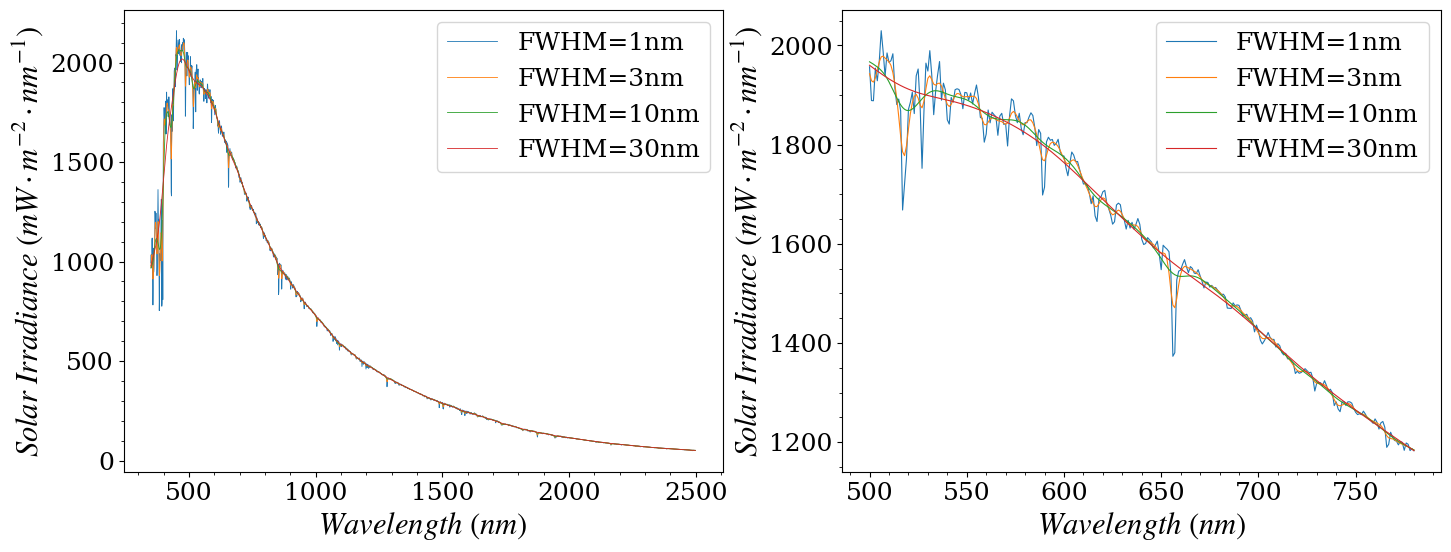

In [5]:

spectral_res=1
central_wl=np.arange(350,2500,spectral_res)

signal = solar_irr.tsis
wl_signal = solar_irr.tsis.wl.values

fig,axs = plt.subplots(1,2,figsize=(17,6))
wl_range=slice(500,780)
for fwhm in [1,3,10,30]:    
    spectral=radoc.Spectral(central_wl,fwhm)
    F0 = spectral.convolve(signal)
    F0.plot(lw=0.6,label='FWHM='+str(fwhm)+'nm',ax=axs[0])
    F0.sel(wl=wl_range).plot(lw=0.8,label='FWHM='+str(fwhm)+'nm',ax=axs[1])

for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Solar\ Irradiance\ (mW\cdot m^{-2}\cdot nm^{-1})$')
    ax.minorticks_on()  
    ax.legend()

## Computation of the top and bottom of atmosphere values

In [6]:
# set Sun zenith angle 
sza=45
# set aerosol optical thickness
aot550=0.2
# tcwv cm into kg.m-2
tpw_cm=4.6
tcwv=tpw_cm*10 

to3_du=300 
pressure=1000

# conversion O3 du to kg.m-2
tco3=to3_du *6.4286e-3/300
tcno2=1e-6/100
tcch4= 1e-2

In [7]:
lut= radoc.LUT(wl=np.arange(350, 2500, 1))
lut.load_auxiliary_data()
lut.lut_preparation(sza=[sza])
gas_trans = radoc.GaseousTransmittance(lut.gas_lut)

INFO:root:loading look-up tables
INFO:root:loading look-up tables
INFO:root:LUT preparation


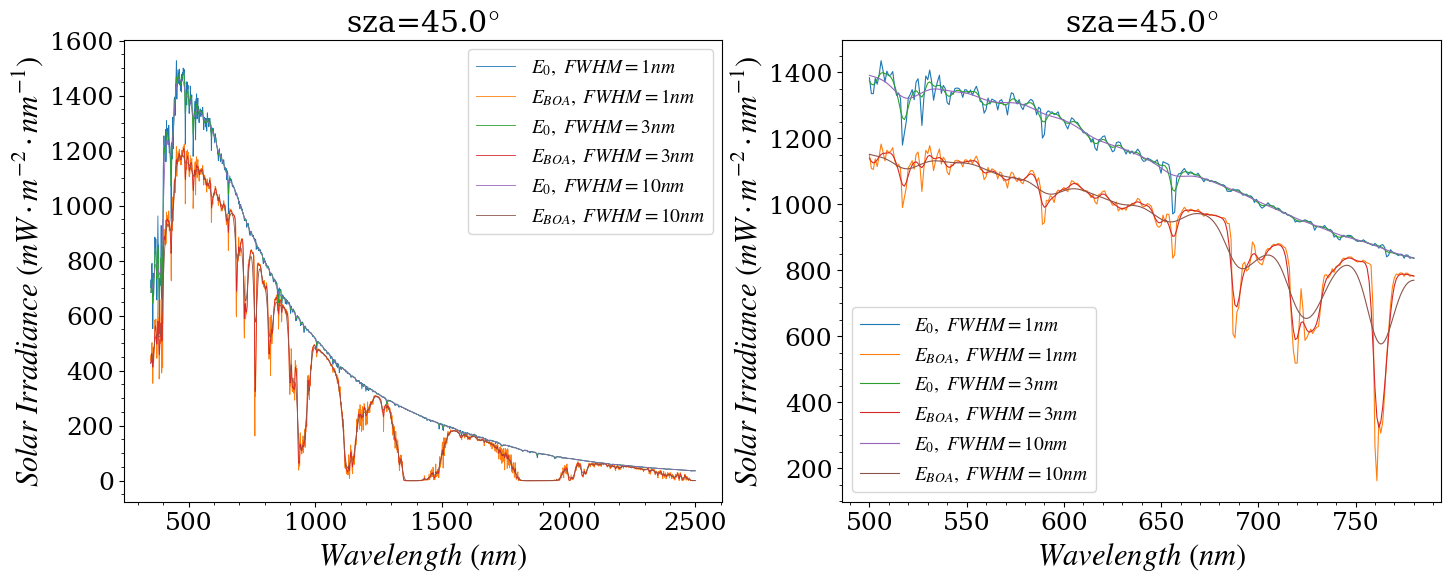

In [8]:
solar_irr=radoc.SolarIrradiance()
fwhm=30.
sza=45
mu0 = np.cos(np.radians(sza))
spectral_res=1
central_wl=np.arange(350,2500,spectral_res)
wl_range=slice(500,780)

Taero_mol = lut.trans_lut.Ttot_Ed.isel(wind=1).interp(sza=sza).isel(model=1).interp(aot_ref=aot550,method='quadratic').interp(wl=central_wl,method='quadratic')

gas_trans.air_mass=1./mu0

gas_trans.coef_abs_scat['h2o'] = 1
gas_trans.coef_abs_scat['ch4'] = 1
Ttot=gas_trans.get_gaseous_transmittance()

fig,axs = plt.subplots(1,2,figsize=(17,6))
for fwhm in [1,3,10]:    
    spectral=radoc.Spectral(central_wl,fwhm)
    F0 = spectral.convolve(solar_irr.tsis)*mu0
    Tg = spectral.convolve(Ttot)
    F0.plot(lw=0.6,label=r'$E_{0},\ FWHM='+str(fwhm)+r'nm$',ax=axs[0])
    F0.sel(wl=wl_range).plot(lw=0.8,label=r'$E_{0},\ FWHM='+str(fwhm)+r'nm$',ax=axs[1])
    Ed=Taero_mol*F0*Tg
    Ed.plot(lw=0.6,label=r'$E_{BOA},\ FWHM='+str(fwhm)+r'nm$',ax=axs[0])
    Ed.sel(wl=wl_range).plot(lw=0.8,label=r'$E_{BOA},\ FWHM='+str(fwhm)+r'nm$',ax=axs[1])
for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Solar\ Irradiance\ (mW\cdot m^{-2}\cdot nm^{-1})$')
    ax.minorticks_on() 
    ax.set_title('sza={:.1f}'.format(sza)+r'$\degree$')
    ax.legend(fontsize=14)

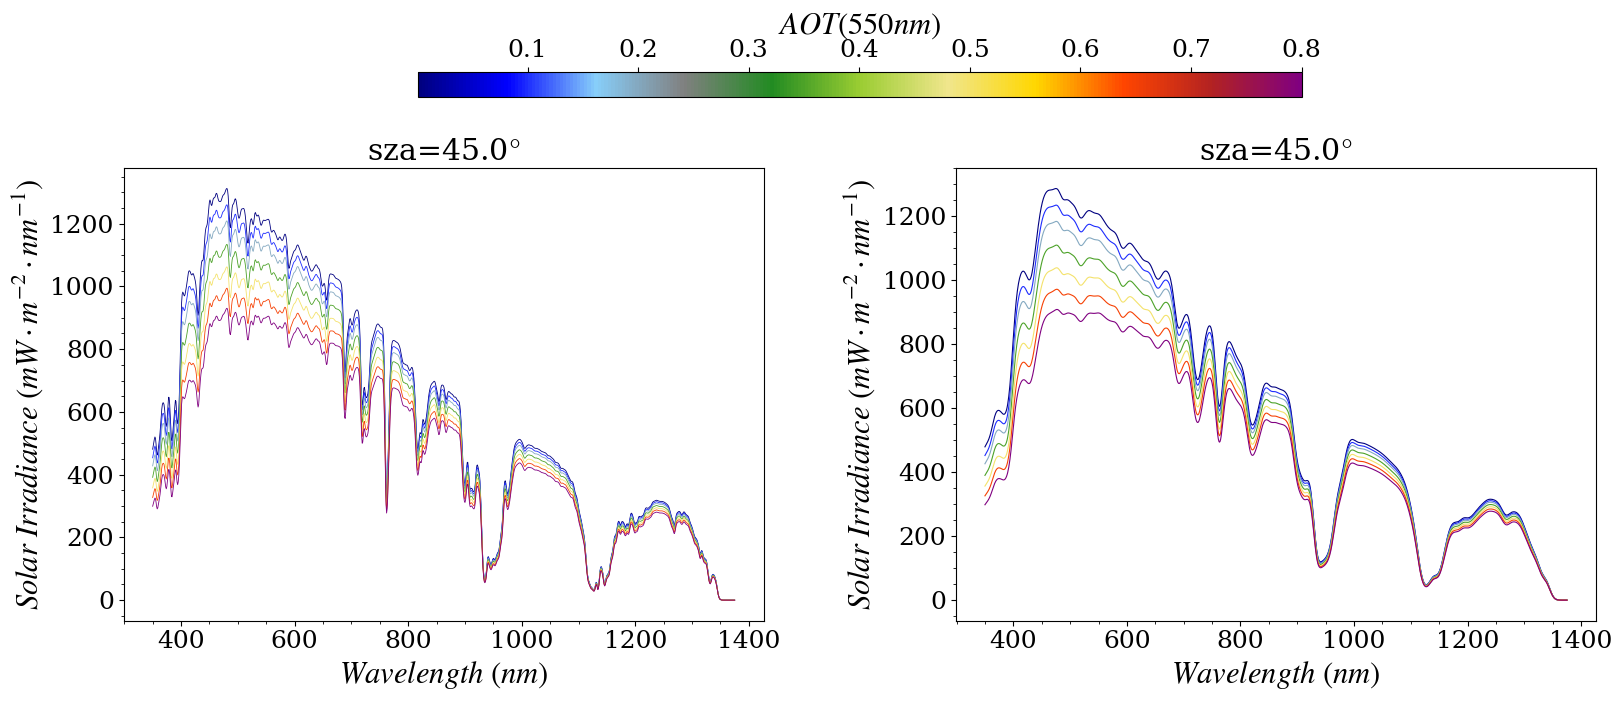

In [20]:
solar_irr=radoc.SolarIrradiance()
fwhm=30.
sza=45
mu0 = np.cos(np.radians(sza))
spectral_res=1
central_wl=np.arange(350,2500,spectral_res)
wl_range=slice(500,780)



wl_range=slice(350,1375)
cmap = mpl.colors.LinearSegmentedColormap.from_list("",
                                                    ['navy', "blue", 'lightskyblue',
                                                     "grey",   'forestgreen','yellowgreen',
                                                     "khaki", "gold",
                                                     'orangered', "firebrick", 'purple'])
norm = mpl.colors.Normalize(vmin=0.001,vmax=0.8)
sm = mpl.cm.ScalarMappable(norm=norm, cmap=cmap)
sm.set_array([])



Taero_mol = lut.trans_lut.Ttot_Ed.isel(wind=1).interp(sza=sza).isel(model=1).interp(aot_ref=aot550,method='quadratic').interp(wl=central_wl,method='quadratic')

gas_trans.air_mass=1./mu0

gas_trans.coef_abs_scat['h2o'] = 1
gas_trans.coef_abs_scat['ch4'] = 1
Ttot=gas_trans.get_gaseous_transmittance()

fig,axs = plt.subplots(1,2,figsize=(19,8))
fig.subplots_adjust( hspace=0.05, wspace=0.3,)

fwhm=3 
spectral=radoc.Spectral(central_wl,fwhm)
F01 = spectral.convolve(solar_irr.tsis)*mu0
Tg1= spectral.convolve(Ttot)
fwhm=10 
spectral=radoc.Spectral(central_wl,fwhm)
F02 = spectral.convolve(solar_irr.tsis)*mu0
Tg2 = spectral.convolve(Ttot)
for aot_ref in [0,0.1,0.2,0.35,0.5,0.65,0.8]:
    Taero_mol = lut.trans_lut.Ttot_Ed.isel(wind=1).interp(sza=sza).isel(model=1).interp(aot_ref=aot_ref,method='quadratic').interp(wl=central_wl,method='quadratic')
    
    
    
    Ed=Taero_mol*F01*Tg1
    Ed.sel(wl=wl_range).plot(lw=0.6,color=cmap(norm(aot_ref)),label=r'$E_{BOA},\ FWHM='+str(fwhm)+r'nm$',ax=axs[0])
    
    Ed=Taero_mol*F02*Tg2
    Ed.sel(wl=wl_range).plot(lw=0.8,color=cmap(norm(aot_ref)),label=r'$E_{BOA},\ FWHM='+str(fwhm)+r'nm$',ax=axs[1])
for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Solar\ Irradiance\ (mW\cdot m^{-2}\cdot nm^{-1})$')
    ax.minorticks_on() 
    ax.set_title('sza={:.1f}'.format(sza)+r'$\degree$')
   # ax.legend(fontsize=14)

cb = fig.colorbar(sm, ax=axs[:], shrink=0.6, aspect=35, pad=0.115, location='top')
cb.set_label(r'$AOT(550nm)$', fontsize=22)

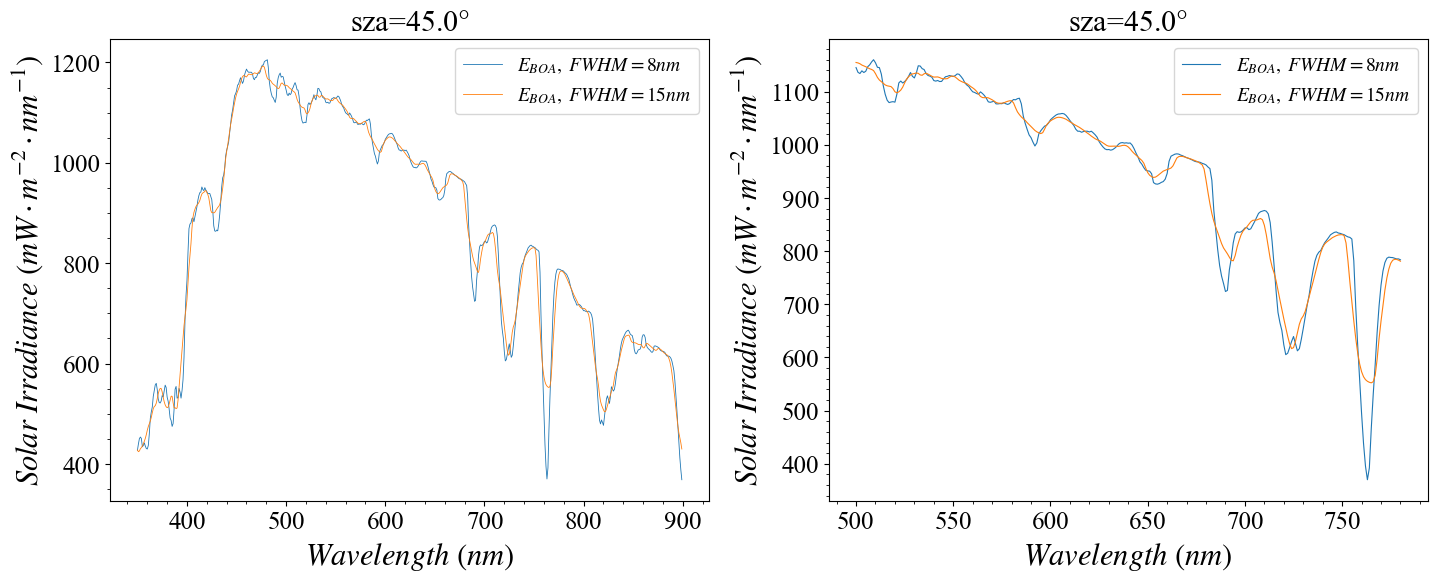

In [58]:
solar_irr=radoc.SolarIrradiance()
fwhm=30.
sza=45
mu0 = np.cos(np.radians(sza))
spectral_res=1
central_wl=np.arange(350,900,spectral_res)
wl_range=slice(500,780)

Taero_mol = lut.trans_lut.Ttot_Ed.isel(wind=1).interp(sza=sza).isel(model=1).interp(aot_ref=aot550,method='quadratic').interp(wl=central_wl,method='quadratic')

gas_trans.air_mass=1./mu0

gas_trans.coef_abs_scat['h2o'] = 1
gas_trans.coef_abs_scat['ch4'] = 1
Ttot=gas_trans.get_gaseous_transmittance()

fig,axs = plt.subplots(1,2,figsize=(17,6))
for fwhm in [8,15]:    
    spectral=radoc.Spectral(central_wl,fwhm)
    F0 = spectral.convolve2(solar_irr.tsis)*mu0
    Tg = spectral.convolve2(Ttot)
    #F0.plot(lw=0.6,label=r'$E_{0},\ FWHM='+str(fwhm)+r'nm$',ax=axs[0])
    #F0.sel(wl=wl_range).plot(lw=0.8,label=r'$E_{0},\ FWHM='+str(fwhm)+r'nm$',ax=axs[1])
    Ed=Taero_mol*F0*Tg
    Ed.plot(lw=0.6,label=r'$E_{BOA},\ FWHM='+str(fwhm)+r'nm$',ax=axs[0])
    Ed.sel(wl=wl_range).plot(lw=0.8,label=r'$E_{BOA},\ FWHM='+str(fwhm)+r'nm$',ax=axs[1])
for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Solar\ Irradiance\ (mW\cdot m^{-2}\cdot nm^{-1})$')
    ax.minorticks_on() 
    ax.set_title('sza={:.1f}'.format(sza)+r'$\degree$')
    ax.legend(fontsize=14)

In [59]:
optosky = pd.read_csv('/DATA/instrument/optosky/1746023693805_2025_04_30_16_34_53.txt',sep='\t', names=['wl','digit'], header=0).set_index('wl').to_xarray()

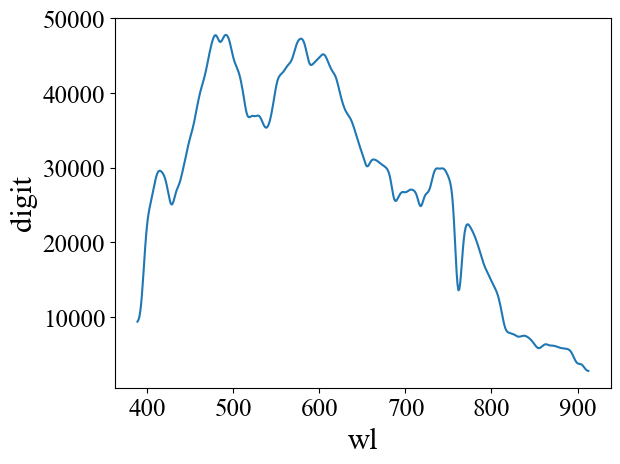

In [60]:
optosky.digit.plot()

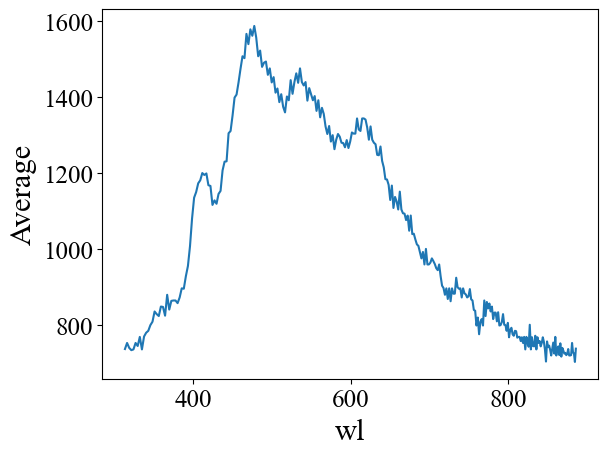

In [61]:
vadim=pd.read_csv('/DATA/instrument/optosky/vadim/Spectralon_ref.csv').rename(columns={'Wavelength[nm]':'wl'}).set_index('wl').to_xarray()
vadim.Average.plot()

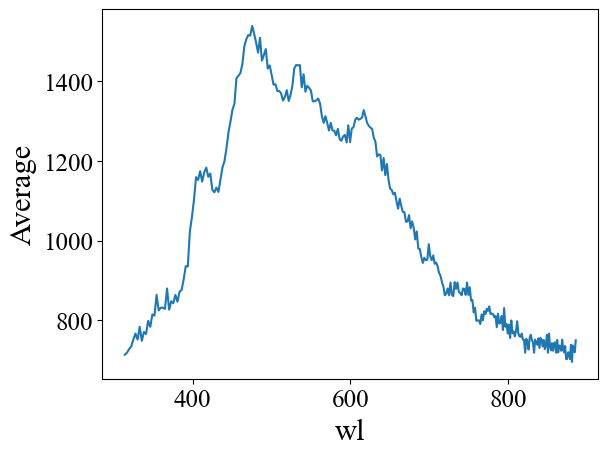

In [62]:
vadim_dark=pd.read_csv('/DATA/instrument/optosky/vadim/Spectralon_Dark.csv').rename(columns={'Wavelength[nm]':'wl'}).set_index('wl').to_xarray()
vadim_dark.Average.plot()

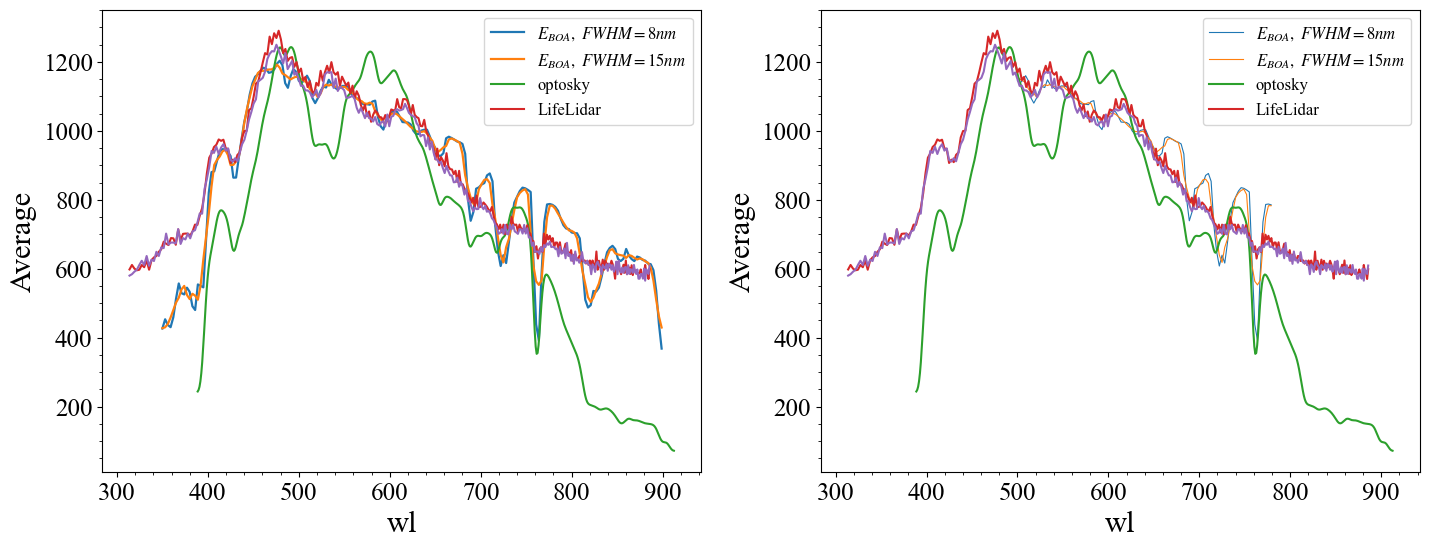

In [68]:
solar_irr=radoc.SolarIrradiance()
fwhm=30.
sza=45
mu0 = np.cos(np.radians(sza))
spectral_res=3
central_wl=np.arange(350,900,spectral_res)
wl_range=slice(500,780)

Taero_mol = lut.trans_lut.Ttot_Ed.isel(wind=1).interp(sza=sza).isel(model=1).interp(aot_ref=aot550,method='quadratic').interp(wl=central_wl,method='quadratic')

gas_trans.air_mass=1./mu0

gas_trans.coef_abs_scat['h2o'] = 1
gas_trans.coef_abs_scat['ch4'] = 1
Ttot=gas_trans.get_gaseous_transmittance()

fig,axs = plt.subplots(1,2,figsize=(17,6))
for fwhm in [8,15]:    
    spectral=radoc.Spectral(central_wl,fwhm)
    F0 = spectral.convolve2(solar_irr.tsis)*mu0
    Tg = spectral.convolve2(Ttot)
    #F0.plot(lw=0.6,label=r'$E_{0},\ FWHM='+str(fwhm)+r'nm$',ax=axs[0])
    #F0.sel(wl=wl_range).plot(lw=0.8,label=r'$E_{0},\ FWHM='+str(fwhm)+r'nm$',ax=axs[1])
    Ed=Taero_mol*F0*Tg
    Ed.plot(lw=1.6,label=r'$E_{BOA},\ FWHM='+str(fwhm)+r'nm$',ax=axs[0])
    Ed.sel(wl=wl_range).plot(lw=0.8,label=r'$E_{BOA},\ FWHM='+str(fwhm)+r'nm$',ax=axs[1])
for ax in  axs:
    ax.set_xlabel(r'$Wavelength\ (nm)$')
    ax.set_ylabel(r'$Solar\ Irradiance\ (mW\cdot m^{-2}\cdot nm^{-1})$')
    ax.minorticks_on() 
    ax.set_title('sza={:.1f}'.format(sza)+r'$\degree$')
    ax.legend(fontsize=14)
    (optosky.digit/50000*1300).plot(ax=ax,label='optosky')
    (vadim.Average/1600*1300).plot(ax=ax,label='LifeLidar')
    (vadim_dark.Average/1600*1300).plot(ax=ax)
    ax.legend(fontsize=12)

In [69]:
vadim

<xarray.Dataset> Size: 7kB
Dimensions:  (wl: 288)
Coordinates:
  * wl       (wl) float64 2kB 313.8 316.5 319.2 321.9 ... 883.3 884.5 885.7
Data variables:
    Average  (wl) float64 2kB 736.0 752.0 739.0 733.0 ... 724.0 702.0 737.0
    1        (wl) int64 2kB 736 752 739 733 735 752 ... 720 752 727 724 702 737